In [1]:
import matplotlib.pyplot as plt
import numpy as np
from simsopt.mhd import Vmec

from spectre import SPECTRE, SPECTREout
from spectre.converters import simsvmec2spectre

%matplotlib inline

## Load VMEC equilibria

Two sources are available:
- `input.iota` — VMEC input file (iota profile, no wout data).
  Converted without interface guesses; SPECTRE linearly interpolates the initial geometry (`linitialize=1`).
- `wout_iota.nc` — VMEC output file.
  Converted with interface geometry guesses interpolated from the VMEC surfaces (`linitialize=0`).

In [2]:
vmec_in  = Vmec("input.iota")
vmec_out = Vmec("wout_iota.nc")

 - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - - -
  VMEC OUTPUT FILES ALREADY EXIST: OVERWRITING THEM ...
  SEQ =    1 TIME SLICE  0.0000E+00
  PROCESSING INPUT.iota
  THIS IS PARVMEC (PARALLEL VMEC), VERSION 9.0
  Lambda: Full Radial Mesh. L-Force: hybrid full/half.

  COMPUTER:    OS:    RELEASE:   DATE = May 14,2026  TIME = 13:21:32


## Convert from `input.iota` (no interface guesses)

`linitialize=1` — SPECTRE linearly interpolates the initial interface geometry from the boundary.

In [11]:
tfluxes = np.linspace(0.0, 1.0, 6, endpoint=True)[1:]  # 5 volumes

params_from_input = simsvmec2spectre(vmec_in, tfluxes=tfluxes, mpol=6, ntor=5, interface_guess='map2disc')

print(f"nvol        : {params_from_input.physics.nvol}")
print(f"lconstraint : {params_from_input.physics.lconstraint}")
print(f"linitialize : {params_from_input.numeric.linitialize}")
print(f"allrzrz     : {params_from_input.physics.allrzrz}")

nvol        : 5
lconstraint : 1
linitialize : 0
allrzrz     : [[[ 0.00000000e+00  1.08340624e+01  1.50139623e+00 ...  0.00000000e+00
    0.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  1.07231912e+01  1.37915704e+00 ...  0.00000000e+00
    0.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  1.06036056e+01  1.25345809e+00 ...  0.00000000e+00
    0.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  1.04756845e+01  1.12448037e+00 ...  0.00000000e+00
    0.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  1.03398073e+01  9.92404853e-01 ...  0.00000000e+00
    0.00000000e+00  0.00000000e+00]]

 [[ 0.00000000e+00  2.52614215e-32 -5.50120847e-01 ...  0.00000000e+00
    0.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  2.78139278e-32 -5.14773728e-01 ...  0.00000000e+00
    0.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  3.06411766e-32 -4.86331476e-01 ...  0.00000000e+00
    0.00000000e+00  0.00000000e+00]
  [ 0.00000000e+00  2.95622790e-32 -4.65701325e-01 ...  0.00000000e+00
    0.000

## Convert from `wout_iota.nc` (with interface guesses)

`linitialize=0` — interface geometry initialised from VMEC surfaces interpolated at each `tflux`.
The `plot=True` option shows the discretised profiles vs the continuous VMEC profiles.

nvol        : 5
lconstraint : 1
linitialize : 0
allrzrz set : True


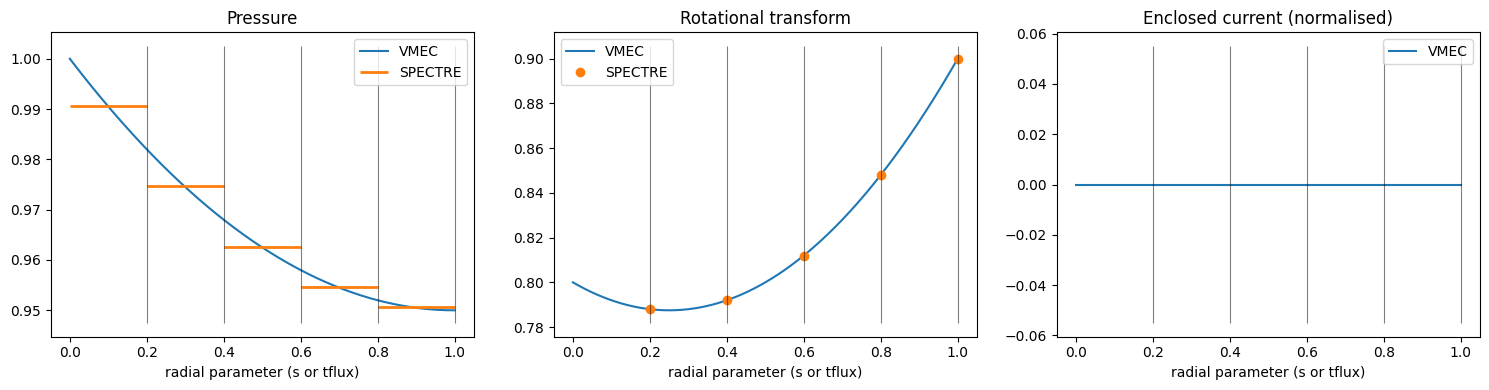

In [8]:
params_from_wout = simsvmec2spectre(vmec_out, tfluxes=tfluxes, mpol=6, ntor=5, plot=True, interface_guess='wout')

print(f"nvol        : {params_from_wout.physics.nvol}")
print(f"lconstraint : {params_from_wout.physics.lconstraint}")
print(f"linitialize : {params_from_wout.numeric.linitialize}")
print(f"allrzrz set : {params_from_wout.physics.allrzrz is not None}")

## Run SPECTRE

Build a `SPECTRE` object from the wout-derived input parameters and run it.
The interface guesses from VMEC give a physically meaningful starting point,
so the initial force residual should be small.

In [9]:
spectre = SPECTRE.from_input_params(params_from_wout, verbose=True)
spectre.run()

readin :            : 
readin :      98.24 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.381320248746204E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  2 ; Nvol=  5 ; Mvol=  5 ; Mpol=  6 ; Ntor=  5 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  1 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad = 10,10,10,10,10,
readin :            : 
readin :      98.24 : Linitialize=  0 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  2.000 ; epsilon=  0.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   0 ; gBntol=  1.00000E-06 ; gBnbld=  6.66000E-01 
rea

readin :            : 
readin :     223.39 : Igeometry=  3 ; enforce_stell_sym=  T ; Lreflect=  0 ; Lbdybnzero= T 
readin :            : Lfreebound=  0 ; phiedge=  1.381320248746202E+02 ; curtor=  0.000000000000000E+00 ; curpol=  0.000000000000000E+00 
readin :            : gamma=  0.000000000000000E+00 
readin :            : Nfp=  2 ; Nvol=  5 ; Mvol=  5 ; Mpol=  6 ; Ntor=  5 
readin :            : pscale=  1.00000E+00 ; Ladiabatic= 0 ; Lconstraint=  1 ; mupf: tol,its=  1.00E-14,   8 
readin :            : Lrad = 10,10,10,10,10,
readin :            : 
readin :     223.39 : Linitialize=  0 ;LautoinitBn=  1 ; Lzerovac= 0 ; Ndiscrete= 2 
readin :            : Nquad=  -1 ; iMpol=  -4 ; iNtor=  -4 
readin :            : 
readin :            : 
readin :            : escale=  0.00000E+00 ; opsilon=  1.00000E+00 ; pcondense=  2.000 ; epsilon=  0.00000E+00 ; wpoloidal        = 1.0000 ; upsilon=  1.00000E+00 
readin :            : mfreeits=   0 ; gBntol=  1.00000E-06 ; gBnbld=  6.66000E-01 
rea

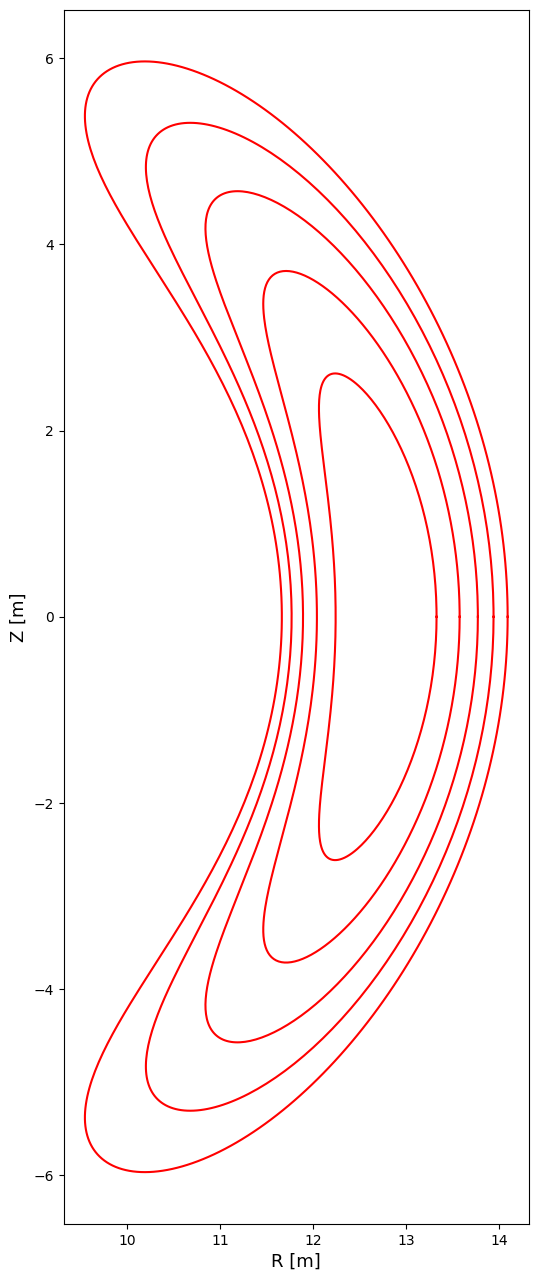

In [14]:
spectre = SPECTRE.from_input_params(params_from_input)
out = spectre.create_spectreout()
out.plot_infaces()

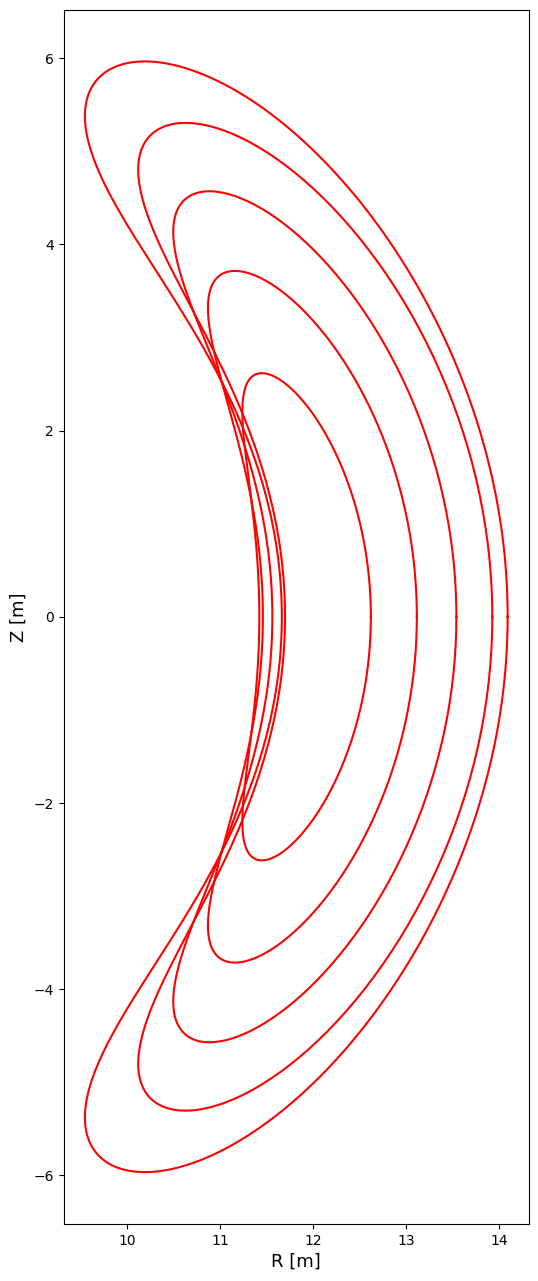